In [1]:
!unzip -q skeleton_clean.zip -d /content

In [2]:
!unzip -q skeleton_data.zip -d /content

In [3]:
# =====================================================================
# VIEW THE STICK FIGURES (paste into ONE Colab cell, run it, then call the functions below)
#   strip("p1_backhand_s1")     -> 8 stick figures across the swing   (needs /content/skeleton_clean)
#   animate("p1_backhand_s1")   -> a small playable animation          (needs /content/skeleton_clean)
#   overlay("/content/p1_backhand_s1.avi", "p1_backhand_s1")
#                               -> green skeleton drawn on the real video frames
#                                  (needs /content/skeleton_data AND the original .avi uploaded)
# =====================================================================
import glob
import numpy as np, cv2
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

EDGES = [(5,7),(7,9),(6,8),(8,10),(5,6),(5,11),(6,12),(11,12),(11,13),(13,15),(12,14),(14,16)]

def find(stem, root="/content/skeleton_clean"):
    hits = glob.glob(f"{root}/*/{stem}.npz")
    assert hits, f"{stem}.npz not found under {root}"
    return hits[0]

def strip(stem, n=8, root="/content/skeleton_clean"):
    seq = np.load(find(stem, root))["seq"]                  # (64 time steps, 17 joints, x/y), torso length = 1
    fig, ax = plt.subplots(1, n, figsize=(2 * n, 4))
    for a, t in zip(ax, np.linspace(0, len(seq) - 1, n).astype(int)):
        for u, v in EDGES:
            a.plot(seq[t, [u, v], 0], seq[t, [u, v], 1], "g-", lw=2)
        a.scatter(seq[t, 5:, 0], seq[t, 5:, 1], c="r", s=12)
        a.set_xlim(-2.5, 2.5); a.set_ylim(3.5, -2.0); a.set_aspect("equal"); a.axis("off")
        a.set_title(f"step {t}", fontsize=8)
    fig.suptitle(stem); plt.show()

def animate(stem, root="/content/skeleton_clean"):
    seq = np.load(find(stem, root))["seq"]
    fig, a = plt.subplots(figsize=(3, 5))
    lines = [a.plot([], [], "g-", lw=2)[0] for _ in EDGES]
    a.set_xlim(-2.5, 2.5); a.set_ylim(3.5, -2.0); a.set_aspect("equal"); a.axis("off"); a.set_title(stem, fontsize=9)
    def update(t):
        for ln, (u, v) in zip(lines, EDGES):
            ln.set_data(seq[t, [u, v], 0], seq[t, [u, v], 1])
        return lines
    anim = FuncAnimation(fig, update, frames=len(seq), interval=80)
    plt.close(fig)
    return HTML(anim.to_jshtml())                            # shows a player with play/pause buttons

def overlay(avi_path, stem, root="/content/skeleton_data", n=6):
    d = np.load(find(stem, root)); k, c = d["kpts"], d["conf"]    # raw skeleton, positions in video pixels
    cap = cv2.VideoCapture(avi_path); tiles = []
    for t in np.linspace(0, len(k) - 1, n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(t)); ok, fr = cap.read()
        if not ok:
            continue
        for u, v in EDGES:
            if c[t, u] > 0.5 and c[t, v] > 0.5:
                cv2.line(fr, tuple(int(x) for x in k[t, u]), tuple(int(x) for x in k[t, v]), (0, 255, 0), 2)
        tiles.append(fr)
    cap.release()
    plt.figure(figsize=(3 * n, 3)); plt.imshow(cv2.cvtColor(np.hstack(tiles), cv2.COLOR_BGR2RGB))
    plt.axis("off"); plt.title(stem); plt.show()

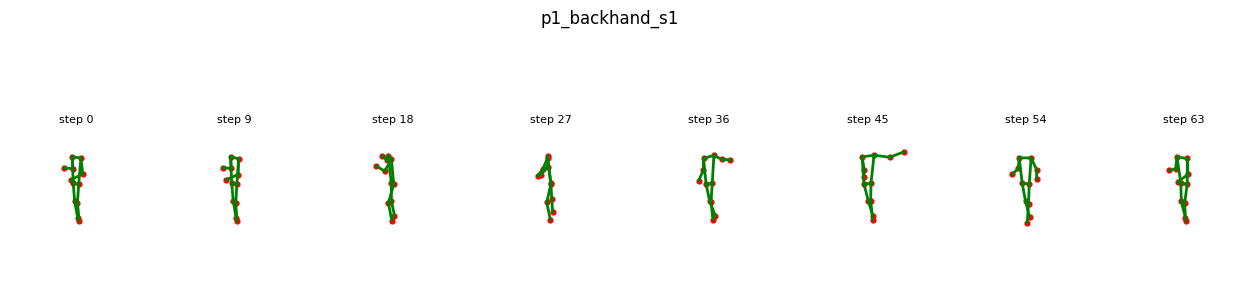

In [4]:
strip("p1_backhand_s1")

In [5]:
animate("p35_smash_s1")

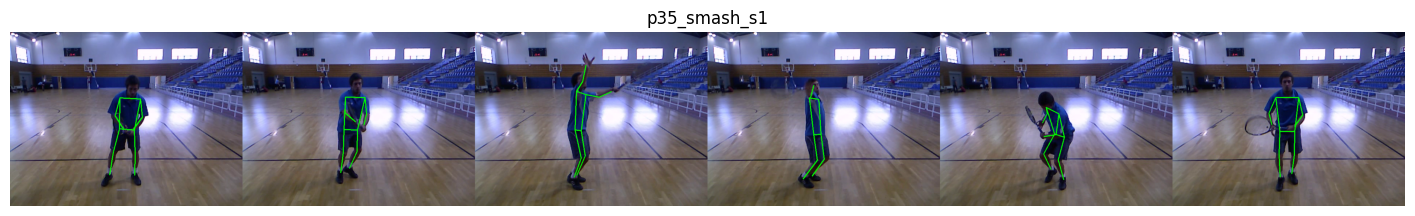

In [6]:
overlay("/content/p35_smash_s1.avi", "p35_smash_s1")

In [11]:
# Upload one video and get a stroke prediction using final ordered Model B.

import os
import sys
import subprocess
import numpy as np
import torch
import torch.nn as nn
import cv2
from google.colab import files

# Install Ultralytics if it is not already available.
try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])
    from ultralytics import YOLO

# Upload the final ordered Model B checkpoint first.
print("Select final_B_seed42.pt")
model_upload = files.upload()
pt_files = [name for name in model_upload if name.lower().endswith(".pt")]

assert len(pt_files) == 1, "Please upload exactly one .pt model file."
checkpoint_path = pt_files[0]
assert "final_b_seed42" in os.path.basename(checkpoint_path).lower(), (
    "Please upload the ordered Model B checkpoint for seed 42."
)
# Upload one video in the second file picker.
print("Now select one tennis video (.avi, .mp4, .mov, or .mkv)")
video_upload = files.upload()
video_extensions = (
    ".avi", ".mp4", ".mov", ".mkv", ".mpeg", ".mpg", ".m4v", ".webm"
)
video_files = [
    name for name in video_upload
    if name.lower().endswith(video_extensions)
]

assert len(video_files) == 1, (
    f"No supported video found. Colab received: {list(video_upload.keys())}"
)
video_path = video_files[0]

CLASS_NAMES = [
    "backhand",
    "backhand2hands",
    "backhand_slice",
    "backhand_volley",
    "flat_service",
    "forehand_flat",
    "forehand_openstands",
    "forehand_slice",
    "forehand_volley",
    "kick_service",
    "slice_service",
    "smash",
]

# Model B architecture, matching the final training script.
class SeqCNN(nn.Module):
    def __init__(self, n=12):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(34, 64, 5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 128, 5, stride=2, padding=2),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Conv1d(128, 128, 3, stride=2, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
        )
        # The final Model B setup did not use video duration.
        self.head = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, n),
        )

    def forward(self, x):
        # Input shape: batch × 64 steps × 17 joints × 2 coordinates
        h = self.conv(x.flatten(2).transpose(1, 2))
        h = torch.cat([h.mean(2), h.amax(2)], dim=1)
        return self.head(h)

# Load the classifier weights.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier = SeqCNN().to(device)

try:
    state = torch.load(
        checkpoint_path, map_location=device, weights_only=True
    )
except TypeError:  # Support older PyTorch versions.
    state = torch.load(checkpoint_path, map_location=device)

classifier.load_state_dict(state)
classifier.eval()

# Load the same pose detector used to extract the project skeletons.
print("Loading YOLO11 pose detector...")
pose_detector = YOLO("yolo11m-pose.pt")
yolo_device = 0 if torch.cuda.is_available() else "cpu"

# Read every frame from the uploaded video.
cap = cv2.VideoCapture(video_path)
frames = []

while True:
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)

cap.release()

assert len(frames) >= 2, (
    "Could not read the video. Check that it is a valid video file."
)

# Detect 17 body points in every frame.
T = len(frames)
kpts = np.full((T, 17, 2), np.nan, dtype=np.float32)
conf = np.zeros((T, 17), dtype=np.float32)
boxes = np.full((T, 4), np.nan, dtype=np.float32)

for start in range(0, T, 16):
    results = pose_detector(
        frames[start:start + 16],
        imgsz=640,
        device=yolo_device,
        verbose=False,
    )

    for offset, result in enumerate(results):
        t = start + offset

        if (
            result.boxes is None
            or len(result.boxes) == 0
            or result.keypoints is None
        ):
            continue

        detected_boxes = result.boxes.xyxy.cpu().numpy()

        # Match the project extraction rule: select the largest person.
        person_i = int(np.argmax(
            (detected_boxes[:, 2] - detected_boxes[:, 0])
            * (detected_boxes[:, 3] - detected_boxes[:, 1])
        ))

        kpts[t] = result.keypoints.xy[person_i].cpu().numpy()

        if result.keypoints.conf is not None:
            conf[t] = result.keypoints.conf[person_i].cpu().numpy()

        boxes[t] = detected_boxes[person_i]

# Clean the detections using the project's preprocessing rules.
CONF_THRESHOLD = 0.5
KEY_JOINTS = [5, 6, 7, 8, 9, 10, 11, 12]
MIN_GOOD_KEY_JOINTS = 6
N_OUT = 64

has_person = ~np.isnan(boxes[:, 0])
height = boxes[:, 3] - boxes[:, 1]

# Require a person detection and 6 of the 8 important joints.
key_ok = (
    (conf[:, KEY_JOINTS] > CONF_THRESHOLD).sum(axis=1)
    >= MIN_GOOD_KEY_JOINTS
) & has_person

# Compare each person's height with a nearby median height.
median_height = np.full(T, np.nan, dtype=np.float32)
half_window = 4

for t in range(T):
    lo = max(0, t - half_window)
    hi = min(T, t + half_window + 1)
    median_height[t] = np.nanmedian(height[lo:hi])

with np.errstate(invalid="ignore", divide="ignore"):
    height_ratio = height / median_height
    size_ok = (
        np.isfinite(height_ratio)
        & (np.maximum(height_ratio, 1.0 / height_ratio) <= 1.5)
    )

# Flag a sudden hip-center jump relative to the person's body height.
hip_center = (kpts[:, 11] + kpts[:, 12]) / 2
body_height = np.nanmedian(height) if has_person.any() else np.nan
hip_spike = np.zeros(T, dtype=bool)

for t in range(1, T - 1):
    if key_ok[t - 1] and key_ok[t] and key_ok[t + 1] and body_height > 0:
        expected_hip = (hip_center[t - 1] + hip_center[t + 1]) / 2
        hip_spike[t] = (
            np.linalg.norm(hip_center[t] - expected_hip) / body_height
            > 0.25
        )

good_frame = key_ok & size_ok & ~hip_spike

# Interpolate unreliable or missing joint coordinates across time.
joint_valid = good_frame[:, None] & (conf > CONF_THRESHOLD)

if (joint_valid[:, [5, 6, 11, 12]].sum(axis=0) == 0).any():
    raise ValueError(
        "Too few reliable shoulder or hip detections. "
        "Try a clearer video with one visible player."
    )

frame_indices = np.arange(T)

for joint in range(17):
    valid = joint_valid[:, joint]

    if valid.sum() == 0:
        kpts[:, joint, :] = np.nan
        continue

    for axis in range(2):
        kpts[:, joint, axis] = np.interp(
            frame_indices,
            frame_indices[valid],
            kpts[valid, joint, axis],
        )

# Center poses on the midpoint between the hips.
hip_center = (kpts[:, 11] + kpts[:, 12]) / 2
shoulder_center = (kpts[:, 5] + kpts[:, 6]) / 2

# If a joint was never detected, place it at the hip center.
for joint in range(17):
    if np.isnan(kpts[:, joint, 0]).any():
        kpts[:, joint, :] = hip_center

# Scale using the median shoulder-to-hip distance.
scale = float(np.median(
    np.linalg.norm(shoulder_center - hip_center, axis=1)
))
if not np.isfinite(scale) or scale < 1e-3:
    scale = 1.0

normalized = (kpts - hip_center[:, None, :]) / scale

# Resample the swing to 64 evenly spaced time steps.
old_times = np.linspace(0, 1, T)
new_times = np.linspace(0, 1, N_OUT)

sequence = np.stack(
    [
        np.stack(
            [
                np.interp(new_times, old_times, normalized[:, joint, axis])
                for axis in range(2)
            ],
            axis=-1,
        )
        for joint in range(17)
    ],
    axis=1,
).astype(np.float32)

# Run the prediction.
input_tensor = torch.from_numpy(sequence).unsqueeze(0).to(device)

with torch.no_grad():
    logits = classifier(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

best_i = int(np.argmax(probabilities))
top_three = np.argsort(probabilities)[::-1][:3]

print(f"\nVideo: {video_path}")
print(f"Predicted stroke: {CLASS_NAMES[best_i]}")
print(f"Model score: {probabilities[best_i] * 100:.1f}%")
print("\nTop three predictions:")
for i in top_three:
    print(f"  {CLASS_NAMES[i]}: {probabilities[i] * 100:.1f}%")

Select final_B_seed42.pt


Saving final_B_seed42.pt to final_B_seed42 (3).pt
Now select one tennis video (.avi, .mp4, .mov, or .mkv)


Saving p1_backhand_s1.avi to p1_backhand_s1 (1).avi
Loading YOLO11 pose detector...

Video: p1_backhand_s1 (1).avi
Predicted stroke: backhand
Model score: 98.0%

Top three predictions:
  backhand: 98.0%
  backhand_volley: 1.0%
  backhand_slice: 0.5%


In [12]:
animate("p1_backhand_s1")

Select one tennis video (.avi, .mp4, .mov, or .mkv)


Saving p1_backhand_s1.avi to p1_backhand_s1 (2).avi
Read 80 frames at 18.00 FPS.
Saved overlay video: p1_backhand_s1 (2)_skeleton_overlay.mp4


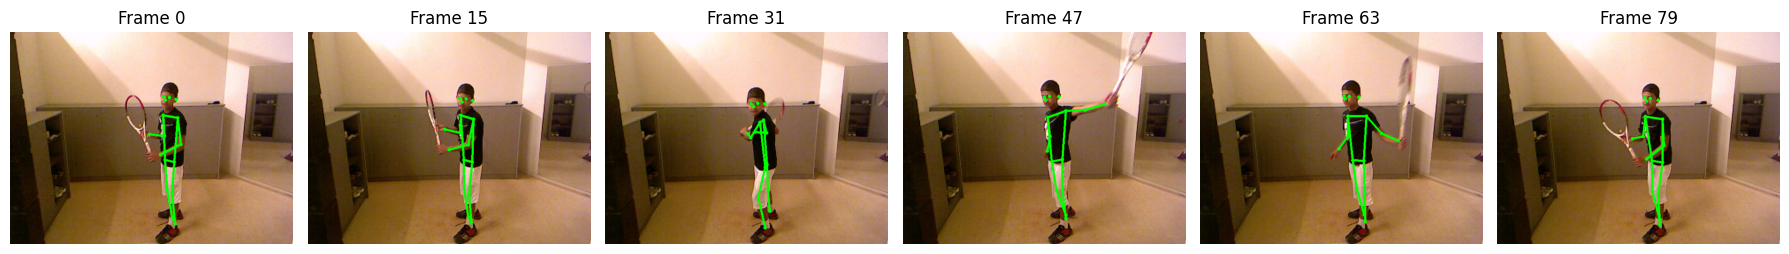

In [13]:
# Upload one video. This cell creates:
# 1) an MP4 with the skeleton overlaid throughout the video
# 2) a six-frame preview strip similar to the reference image

import os
import sys
import subprocess
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import Video, display

# Install Ultralytics if needed.
try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ultralytics"
    ])
    from ultralytics import YOLO

# Upload one video.
print("Select one tennis video (.avi, .mp4, .mov, or .mkv)")
uploaded = files.upload()
video_extensions = (".avi", ".mp4", ".mov", ".mkv", ".mpeg", ".mpg", ".m4v", ".webm")
video_files = [
    name for name in uploaded
    if name.lower().endswith(video_extensions)
]
assert len(video_files) == 1, (
    f"Upload one supported video. Colab received: {list(uploaded.keys())}"
)
video_path = video_files[0]

# These are the same body connections used in the project's skeleton viewer.
EDGES = [
    (5, 7), (7, 9),       # left shoulder, elbow, wrist
    (6, 8), (8, 10),      # right shoulder, elbow, wrist
    (5, 6),               # shoulders
    (5, 11), (6, 12),     # shoulders to hips
    (11, 12),             # hips
    (11, 13), (13, 15),   # left hip, knee, ankle
    (12, 14), (14, 16),   # right hip, knee, ankle
]

# Read the video.
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
if not fps or fps <= 0:
    fps = 25.0

frames = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frames.append(frame)
cap.release()

assert frames, "Could not read frames from the uploaded video."

height, width = frames[0].shape[:2]
print(f"Read {len(frames)} frames at {fps:.2f} FPS.")

# Load the pose detector. It may download yolo11m-pose.pt on first use.
pose_model = YOLO("yolo11m-pose.pt")
device = 0 if __import__("torch").cuda.is_available() else "cpu"

# Detect poses and draw the largest detected person in each frame.
overlay_frames = []
for start in range(0, len(frames), 16):
    batch = frames[start:start + 16]
    results = pose_model(
        batch,
        imgsz=640,
        device=device,
        verbose=False,
    )

    for offset, result in enumerate(results):
        frame = batch[offset].copy()

        if (
            result.boxes is not None
            and len(result.boxes) > 0
            and result.keypoints is not None
        ):
            boxes = result.boxes.xyxy.cpu().numpy()
            # Match the project's original extraction rule: choose the largest person.
            person_i = int(np.argmax(
                (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
            ))

            points = result.keypoints.xy[person_i].cpu().numpy()
            if result.keypoints.conf is not None:
                confidence = result.keypoints.conf[person_i].cpu().numpy()
            else:
                confidence = np.ones(17, dtype=np.float32)

            # Draw a green line only when both connected joints are confident.
            for a, b in EDGES:
                if confidence[a] > 0.5 and confidence[b] > 0.5:
                    pa = tuple(np.round(points[a]).astype(int))
                    pb = tuple(np.round(points[b]).astype(int))
                    cv2.line(frame, pa, pb, (0, 255, 0), 3)

            # Draw visible joints.
            for j in range(17):
                if confidence[j] > 0.5:
                    point = tuple(np.round(points[j]).astype(int))
                    cv2.circle(frame, point, 4, (0, 255, 0), -1)

        overlay_frames.append(frame)

# Save the overlaid animation as an MP4.
stem = os.path.splitext(os.path.basename(video_path))[0]
output_video = f"{stem}_skeleton_overlay.mp4"
writer = cv2.VideoWriter(
    output_video,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),
)

for frame in overlay_frames:
    writer.write(frame)
writer.release()

print(f"Saved overlay video: {output_video}")

# Show a six-frame strip similar to your reference.
sample_indices = np.linspace(
    0, len(overlay_frames) - 1, min(6, len(overlay_frames))
).astype(int)

fig, axes = plt.subplots(
    1, len(sample_indices),
    figsize=(3 * len(sample_indices), 3)
)
if len(sample_indices) == 1:
    axes = [axes]

for ax, index in zip(axes, sample_indices):
    rgb = cv2.cvtColor(overlay_frames[index], cv2.COLOR_BGR2RGB)
    ax.imshow(rgb)
    ax.set_title(f"Frame {index}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Play the full overlaid video in Colab.
display(Video(output_video, embed=True, width=800))

# To download the MP4 to your computer, uncomment and run this:
# files.download(output_video)